# **De Montmort's Matching Problem**

**Probability · Permutations · Monte Carlo Simulation**
___


Suppose \(n\) cards are numbered \(1,2,.....,n\). The cards are shuffled uniformly at random and placed into positions \(1,2,........n\).

A match occurs whenever card \(j\) is placed in position \(j\). The question is to determine the probability that at least one such match occurs.

For example, if the shuffled arrangement is

$$
[3,\,1,\,2,\,4,\,5]
$$

cards 4 and 5 remain in their original positions, so this arrangement contains two matches.

This notebook investigates the matching probability using combinatorial probability and computational experiments. We will compare theoretical results with Monte Carlo estimates and examine how the probability behaves as the number of cards increases.

### **Assumptions**

* Every permutation of the \(n\) cards is equally likely.
* Each card appears exactly once.
* A match occurs when a card's number equals its position.
* The event of interest is **at least one match**, not exactly one match.


___
### **1.    Mathematical model**

There are \(n!\) possible permutations of \(n\) distinct cards, and each is equally likely.

A derangement is a permutation in which no element remains in its original position. Let \(!n\) denote the number of derangements.

The probability of no match is therefore

$$
P(\text{no match})=\frac{!n}{n!}.
$$

Using the Inclusion–Exclusion Principle, the derangement probability can be expressed as

$$
P(\text{no match})
=
\sum_{j=0}^{n}\frac{(-1)^j}{j!}.
$$

Taking the complementary event gives

$$
\boxed{
P(\text{at least one match})
=
1-\sum_{j=0}^{n}\frac{(-1)^j}{j!}
}
$$

Equivalently,

$$
\boxed{
P(\text{at least one match})
=
\sum_{j=1}^{n}\frac{(-1)^{j+1}}{j!}
}
$$

As \(n\) increases, the probability approaches

$$
\boxed{
1-\frac{1}{e}\approx 0.63212
}
$$

The simulation will estimate the same probability by generating random permutations and recording whether each contains at least one fixed point.


#### Import the required libraries.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#### Consistent plotting style.

In [2]:
plt.style.use("seaborn-v0_8-whitegrid")

plt.rcParams.update({
    "figure.figsize": (11, 6),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "legend.frameon": False
})

___
### **2.  Theoretical probability**

The exact probability provides a reference against which the simulation can be evaluated.

We will calculate the finite-\(n\) probability using the alternating factorial sum. This avoids enumerating all \(n!\) permutations, which becomes impractical even for moderately large \(n\).

The result will be used throughout the notebook to assess the accuracy of the Monte Carlo estimates.


#### Implementing the formula. (Factorial Sum formula)

In [3]:
def matching_probability(n):
    if not isinstance(n, (int, np.integer)) or isinstance(n, (bool, np.bool_)):
        raise TypeError("n must be a positive integer.")

    if n < 1:
        raise ValueError("n must be at least 1.")

    term = 1.0
    p_match = 0.0

    for j in range(1, n + 1):
        term /= j
        p_match += term if j % 2 == 1 else -term

    return p_match

#### Check small values.

In [5]:
small_n_results = pd.DataFrame({
    "Number of Cards": range(1, 11),
    "Theoretical Probability": [
        matching_probability(n)
        for n in range(1, 11)
    ]
})

small_n_results["Probability (%)"] = (
    small_n_results["Theoretical Probability"] * 100
)

small_n_results

,Number of Cards,Theoretical Probability,Probability (%)
0,1,1.000000,100.000000
1,2,0.500000,50.000000
2,3,0.666667,66.666667
3,4,0.625000,62.500000
4,5,0.633333,63.333333
5,6,0.631944,63.194444
6,7,0.632143,63.214286
7,8,0.632118,63.211806
8,9,0.632121,63.212081
9,10,0.632121,63.212054


___
### **3. Monte Carlo Simulation**

The theoretical solution gives us the exact probability of obtaining at least one match. We will now estimate this probability experimentally using Monte Carlo simulation.

The simulation follows four steps:

1. Create a set of cards numbered from \(1\) to \(n\).
2. Randomly shuffle the cards.
3. Check whether at least one card occupies its matching position.
4. Repeat the experiment many times and calculate the proportion of experiments containing at least one match.

For \(N\) independent trials, the estimated probability is

$$
\boxed{
\hat{P}(\text{at least one match})
=
\frac{\text{Number of trials with at least one match}}{N}
}
$$

As the number of trials increases, the simulated probability should generally approach the theoretical probability.


#### Perform one random experiment.

Before running thousands of experiments, i am simulating just one shuffle and inspect what happens.

In [13]:
rng = np.random.default_rng(42)

n = 10
cards = np.arange(1, n + 1)

arrangement = rng.permutation(cards)

positions = np.arange(1, n + 1)
matches = arrangement == positions

experiment = pd.DataFrame({
    "Position": positions,
    "Card": arrangement,
    "Match": matches
})

experiment

,Position,Card,Match
0,1,6,False
1,2,7,False
2,3,1,False
3,4,8,False
4,5,4,False
5,6,3,False
6,7,5,False
7,8,10,False
8,9,2,False
9,10,9,False


This experiment therefore hasn't at least one match, but it doesn't mean that probability of getting at least one match is 0. This is just a single shuffle, we will stimulate it for 100,000 independent shuffle and look over its combined probability of getting at least one match.

In [14]:
n = 10
n_simulations = 100_000

cards = np.arange(1, n + 1)
positions = np.arange(1, n + 1)

all_arrangements = rng.permuted(
    np.tile(cards, (n_simulations, 1)),
    axis=1
)

matches_per_trial = np.any(
    all_arrangements == positions,
    axis=1
)

successful_trials = matches_per_trial.sum()

simulated_probability = matches_per_trial.mean()
theoretical_probability = matching_probability(n)

print(f"Number of cards: {n}")
print(f"Total simulations: {n_simulations:,}")
print(f"Trials with at least one match: {successful_trials:,}")
print(f"Simulated probability: {simulated_probability:.4%}")
print(f"Theoretical probability: {theoretical_probability:.4%}")

Number of cards: 10
Total simulations: 100,000
Trials with at least one match: 63,207
Simulated probability: 63.2070%
Theoretical probability: 63.2121%


#### **Result**

Our first random shuffle produced no matching cards. However, that single outcome does not imply that the probability of obtaining at least one match is zero.

A random experiment produces one outcome. Probability describes the likelihood of an event across the underlying random process.

For ten cards, the theoretical probabilities are

$$
P(\text{no match})\approx 0.367879
$$

and

$$
P(\text{at least one match})\approx 0.632121.
$$

Consequently, approximately 36.79% of random shuffles contain no matches, while approximately 63.21% contain at least one match.

Our first experiment simply produced one of the possible outcomes. The Monte Carlo simulation provides a much broader picture by repeating the experiment independently many times.

**Key insight:** An individual outcome can differ from what is most likely, and even a large simulation is subject to random variation. The goal is not to reproduce the theoretical probability exactly in every run, but to estimate it reliably.


### Quantify the simulation error.

In [15]:
p = theoretical_probability
p_hat = simulated_probability
N = n_simulations

standard_error = np.sqrt(p * (1 - p) / N)

absolute_error = abs(p_hat - p)
relative_error = absolute_error / p

lower_bound = p_hat - 1.96 * standard_error
upper_bound = p_hat + 1.96 * standard_error

error_summary = pd.DataFrame({
    "Metric": [
        "Theoretical probability",
        "Simulated probability",
        "Absolute error (percentage points)",
        "Relative error (%)",
        "Monte Carlo standard error (percentage points)",
        "Approximate 95% interval lower bound",
        "Approximate 95% interval upper bound"
    ],
    "Value": [
        p,
        p_hat,
        absolute_error * 100,
        relative_error * 100,
        standard_error * 100,
        lower_bound,
        upper_bound
    ]
})

error_summary

,Metric,Value
0,Theoretical probability,0.632121
1,Simulated probability,0.632070
2,Absolute error (percentage points),0.005054
3,Relative error (%),0.007995
4,Monte Carlo standard error (percentage points),0.152494
5,Approximate 95% interval lower bound,0.629081
6,Approximate 95% interval upper bound,0.635059


The interval here is an approximate 95% interval for the underlying probability, using the normal approximation to the binomial distribution. It is not a guarantee that every simulation will fall inside those bounds.

### Plots

Visual Enhancement

In [16]:
import matplotlib as mpl
from matplotlib.ticker import PercentFormatter

COLORS = {
    "background": "#0B1020",
    "panel": "#121A2B",
    "text": "#F1F5F9",
    "muted": "#94A3B8",
    "cyan": "#22D3EE",
    "coral": "#FB7185",
    "gold": "#FBBF24",
    "green": "#34D399",
    "grid": "#293449"
}

mpl.rcParams.update({
    "figure.facecolor": COLORS["background"],
    "axes.facecolor": COLORS["panel"],
    "axes.edgecolor": COLORS["grid"],
    "axes.labelcolor": COLORS["text"],
    "axes.titlecolor": COLORS["text"],
    "xtick.color": COLORS["muted"],
    "ytick.color": COLORS["muted"],
    "text.color": COLORS["text"],
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "legend.frameon": False,
    "savefig.facecolor": COLORS["background"],
    "savefig.dpi": 200
})

#### **The Probability Fingerprint**

What fraction of the 100,000 shuffles produced at least one match, and how does it compare with theory?

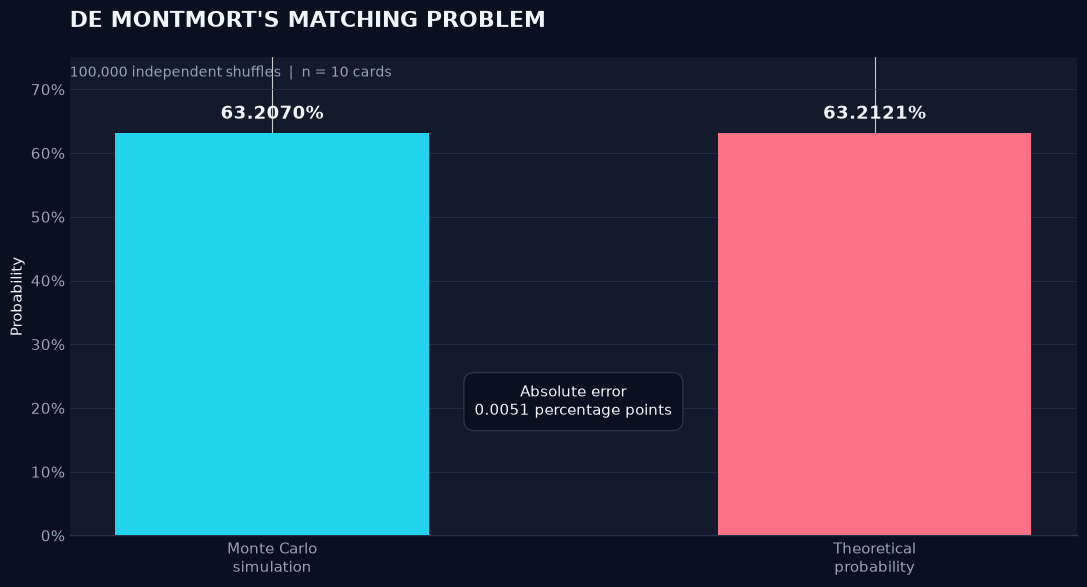

In [17]:
fig, ax = plt.subplots(figsize=(11, 6))

labels = ["Monte Carlo\nsimulation", "Theoretical\nprobability"]
values = [p_hat, p]

bars = ax.bar(
    labels,
    values,
    width=0.52,
    color=[COLORS["cyan"], COLORS["coral"]],
    edgecolor="none",
    zorder=3
)

ax.set_ylim(0, 0.75)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylabel("Probability")
ax.set_title(
    "DE MONTMORT'S MATCHING PROBLEM",
    loc="left",
    pad=22
)

ax.text(
    0, 0.96,
    f"{N:,} independent shuffles  |  n = 10 cards",
    transform=ax.transAxes,
    color=COLORS["muted"],
    fontsize=10
)

for bar, value in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.015,
        f"{value:.4%}",
        ha="center",
        va="bottom",
        fontsize=13,
        fontweight="bold"
    )

ax.text(
    0.5, 0.28,
    f"Absolute error\n{absolute_error * 100:.4f} percentage points",
    transform=ax.transAxes,
    ha="center",
    va="center",
    color=COLORS["text"],
    bbox={
        "boxstyle": "round,pad=0.7",
        "facecolor": COLORS["background"],
        "edgecolor": COLORS["grid"]
    }
)

ax.grid(axis="y", color=COLORS["grid"], alpha=0.65, zorder=0)
ax.spines[["top", "right", "left"]].set_visible(False)

plt.tight_layout()
plt.show()

The two estimates are nearly indistinguishable at this scale. That's evidence of agreement between the theoretical calculation and this particular simulation.

The annotation makes the numerical difference explicit rather than relying on visual inspection.

However, this plot doesn't demonstrate convergence. It compares just one simulation with the theoretical result. For that, we need a more informative visualization.

#### **Convergence: watch the estimate stabilize**

Instead of looking only at the final result, we'll examine how the estimated probability changes as the number of trials increases.

For the first \(m\) simulations, define the running estimate as

$$ \hat p_m=\frac{1}{m}\sum_{i=1}^{m}X_i $$

where \(X_i​=1\) if trial \(i\) contains at least one match and \(X_i=0\) otherwise.

As \(m\) increases, the running estimate should generally stabilize around the theoretical probability.

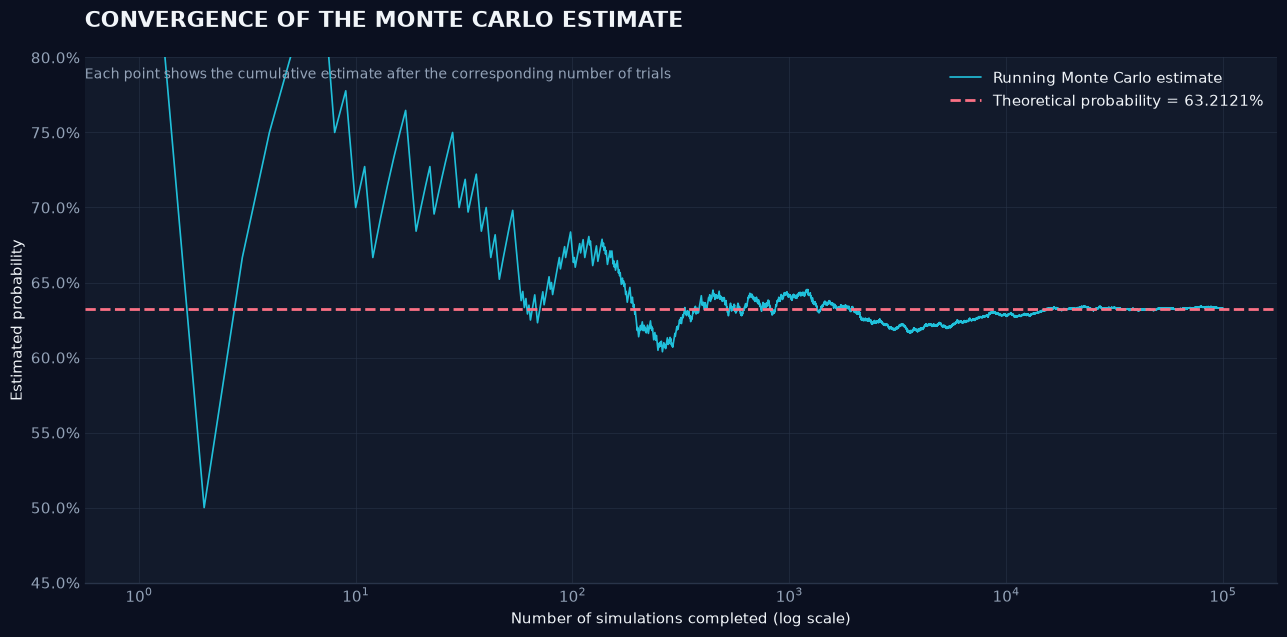

In [18]:
N_convergence = 100_000

convergence_arrangements = rng.permuted(
    np.tile(cards, (N_convergence, 1)),
    axis=1
)

convergence_successes = np.any(
    convergence_arrangements == positions,
    axis=1
)

running_probability = (
    np.cumsum(convergence_successes) /
    np.arange(1, N_convergence + 1)
)

trial_numbers = np.arange(1, N_convergence + 1)

fig, ax = plt.subplots(figsize=(13, 6.5))

ax.plot(
    trial_numbers,
    running_probability,
    color=COLORS["cyan"],
    linewidth=1.2,
    alpha=0.9,
    label="Running Monte Carlo estimate"
)

ax.axhline(
    p,
    color=COLORS["coral"],
    linestyle="--",
    linewidth=2,
    label=f"Theoretical probability = {p:.4%}"
)

ax.set_xscale("log")
ax.set_ylim(0.45, 0.80)
ax.yaxis.set_major_formatter(PercentFormatter(1))

ax.set_xlabel("Number of simulations completed (log scale)")
ax.set_ylabel("Estimated probability")
ax.set_title(
    "CONVERGENCE OF THE MONTE CARLO ESTIMATE",
    loc="left",
    pad=22
)

ax.text(
    0, 0.96,
    "Each point shows the cumulative estimate after the corresponding number of trials",
    transform=ax.transAxes,
    color=COLORS["muted"],
    fontsize=10
)

ax.grid(color=COLORS["grid"], alpha=0.55)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

At the beginning, a single success or failure can change the estimate dramatically.
The dashed line represents the theoretical probability. The running estimate should fluctuate around that line and generally settle closer to it as the sample grows.

This illustrates the intuition behind the law of large numbers. It does not imply that every additional trial must bring the estimate closer to theory.

#### **How does uncertainty shrink?**

Convergence is easier to understand when we quantify uncertainty.

For independent Bernoulli trials, the standard error of the sample proportion decreases approximately as

$$ SE(\hat p)\propto\frac{1}{\sqrt{N}} $$

That relationship is important: increasing the number of simulations by a factor of 100 reduces the standard error by a factor of 10, not 100.

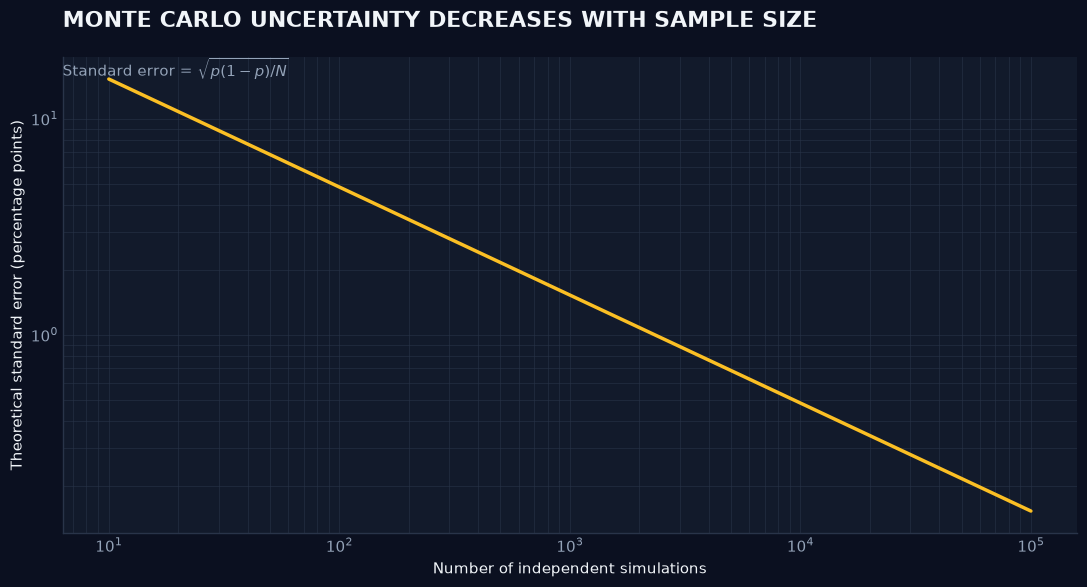

In [19]:
simulation_counts = np.unique(
    np.logspace(1, 5, 150).astype(int)
)

standard_errors = np.sqrt(
    p * (1 - p) / simulation_counts
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    simulation_counts,
    standard_errors * 100,
    color=COLORS["gold"],
    linewidth=2.5
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("Number of independent simulations")
ax.set_ylabel("Theoretical standard error (percentage points)")
ax.set_title(
    "MONTE CARLO UNCERTAINTY DECREASES WITH SAMPLE SIZE",
    loc="left",
    pad=22
)

ax.text(
    0, 0.96,
    r"Standard error = $\sqrt{p(1-p)/N}$",
    transform=ax.transAxes,
    color=COLORS["muted"],
    fontsize=11
)

ax.grid(color=COLORS["grid"], alpha=0.55, which="both")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

The line slopes downward because larger simulations produce more precise estimates on average.

The logarithmic axes make the scaling relationship easier to see.

This is useful when deciding how many simulations to run. Going from 10,000 to 100,000 trials improves precision, but it doesn't eliminate randomness. The benefit of adding more simulations gradually diminishes.

#### **The distribution of matches**

So far, we've treated each shuffle as a binary outcome:

- At least one match.
- No matches.

But we're throwing away information when we reduce the entire permutation to True or False.

A shuffle could contain zero matches, one match, two matches, or more.
Let's investigate the number of fixed points in each random permutation.

In [20]:
N_distribution = 100_000
n_distribution = 10

distribution_cards = np.arange(1, n_distribution + 1)

distribution_arrangements = rng.permuted(
    np.tile(distribution_cards, (N_distribution, 1)),
    axis=1
)

match_counts = np.sum(
    distribution_arrangements == distribution_cards,
    axis=1
)

observed_counts = (
    pd.Series(match_counts)
    .value_counts()
    .sort_index()
)

distribution_table = pd.DataFrame({
    "Number of matches": np.arange(n_distribution + 1)
})

distribution_table["Observed trials"] = (
    distribution_table["Number of matches"]
    .map(observed_counts)
    .fillna(0)
    .astype(int)
)

distribution_table["Observed probability"] = (
    distribution_table["Observed trials"] / N_distribution
)

distribution_table

,Number of matches,Observed trials,Observed probability
0,0,36842,0.36842
1,1,36679,0.36679
2,2,18404,0.18404
3,3,6212,0.06212
4,4,1502,0.01502
5,5,307,0.00307
6,6,49,0.00049
7,7,4,0.00004
8,8,1,0.00001
9,9,0,0.00000


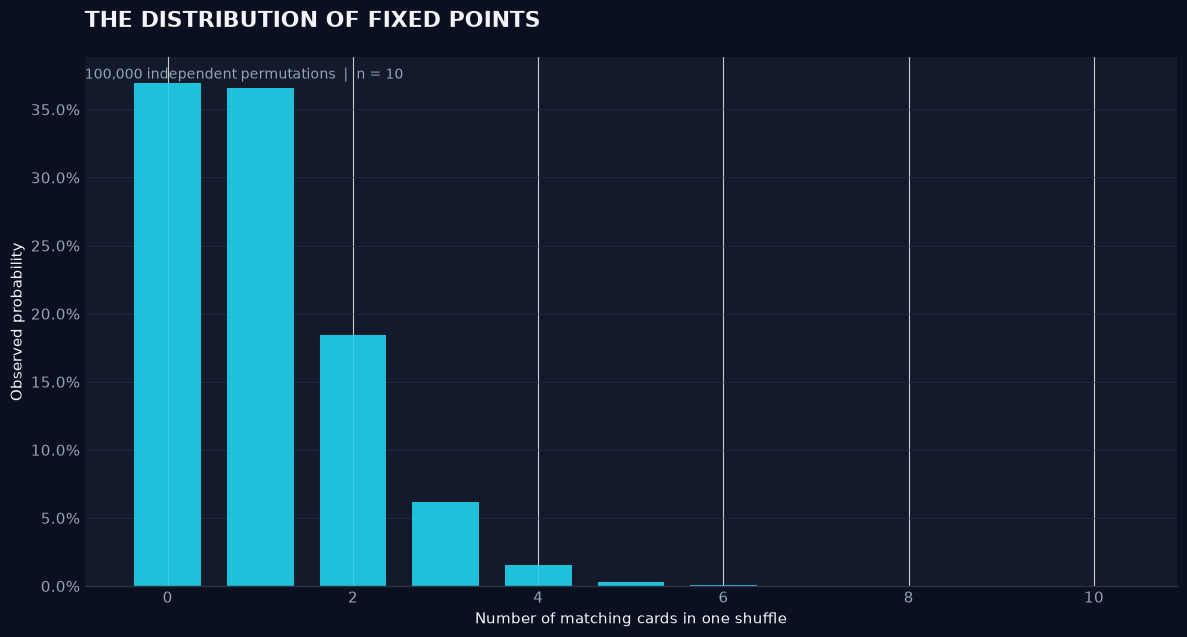

In [22]:
fig, ax = plt.subplots(figsize=(12, 6.5))

x = distribution_table["Number of matches"]
observed = distribution_table["Observed probability"]

ax.bar(
    x,
    observed,
    width=0.72,
    color=COLORS["cyan"],
    alpha=0.9,
    edgecolor="none"
)

ax.set_xlabel("Number of matching cards in one shuffle")
ax.set_ylabel("Observed probability")
ax.set_title(
    "THE DISTRIBUTION OF FIXED POINTS",
    loc="left",
    pad=22
)

ax.yaxis.set_major_formatter(PercentFormatter(1))

ax.text(
    0, 0.96,
    f"{N_distribution:,} independent permutations  |  n = {n_distribution}",
    transform=ax.transAxes,
    color=COLORS["muted"],
    fontsize=10
)

ax.grid(axis="y", color=COLORS["grid"], alpha=0.55)
ax.spines[["top", "right", "left"]].set_visible(False)

plt.tight_layout()
plt.show()

For a random permutation of ten cards:

Zero matches occur frequently.
Exactly one match is also common.
Two matches occur less frequently.
Larger numbers of simultaneous matches become progressively less common.

The distribution gives us a richer understanding of the process than the original binary event alone.

Notice also that the number of matches is not binomially distributed in the usual independent-trials sense across card positions. Within a single permutation, the card positions are dependent: placing one card changes the possible placements of the others.

___

### **4. Conclusion**

#### Key findings

1. **A single random outcome does not determine a probability.** Our first shuffle produced no matches, but repeated independent experiments revealed that matches occur in approximately 63.2% of permutations of ten cards.

2. **Monte Carlo simulation can validate theoretical results.** With 100,000 simulations, our estimated probability was 63.2070%, compared with the theoretical value of approximately 63.2121%.

3. **Simulation estimates fluctuate because of randomness.** The difference between theory and simulation is expected. Standard errors help us quantify the amount of variation that is reasonable.

4. **More simulations generally improve precision.** The standard error of the estimated probability decreases at a rate proportional to \(1/\sqrt{N}\).

5. **The full distribution reveals more than a binary outcome.** Counting the number of matching cards provides additional insight into the structure of random permutations.

6. **The probability approaches a constant as the number of cards grows.** As \(n\) tends to infinity, the probability of at least one match approaches

$$
1-\frac{1}{e}\approx 0.632121.
$$

#### Final takeaway

Theoretical probability tells us what to expect mathematically. Monte Carlo simulation lets us investigate that expectation experimentally, measure uncertainty, and visualize how random outcomes behave.

The most valuable result is not simply that our simulation produced a number close to 63.2%. It is that we can explain why this agreement is expected, quantify the uncertainty, and investigate the behavior of the system beyond the original probability question.


___
_Thanks for reading._

by 

**Abdur Rahman (Rahven)**
___